# ЛР 1 - Дополнительный раунд улучшения

Ростислав Манзюк, GitHub: grinchaus

Проверяю семантическую историю автора и обучаемую нейросеть на E5-векторах. Сравниваю результат с отправленной версией и исходным baseline. Новый комплект находится в `submission-v2/`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
assert (ROOT / "run_lab1_v2.py").is_file(), "Открой notebook из корня репозитория"
DATA = ROOT / "data"
RESULTS = ROOT / "results" / "lab1-v2"
OUTPUT = ROOT / "submission-v2"
config = json.loads((OUTPUT / "selection.json").read_text())

def run(*args):
    subprocess.run([sys.executable, *map(str, args)], cwd=ROOT, check=True)

assert (DATA / "labels.csv").is_file(), "Нужен официальный распакованный датасет"
display(config)

{'name': 'semantic_tree+text:selected+dense_ensemble:0.3',
 'tree': 'semantic_tree',
 'neural': 'dense_ensemble',
 'neural_weight': 0.3,
 'blend': {'validation_macro_f1': 0.6731241284992583,
  'tree_weight': [0.9, 0.5, 0.9],
  'class_weights': [0.75, 1.0, 0.6]},
 'validation': {'42': {'macro_f1': 0.6766, 'qwk': 0.6203, 'accuracy': 0.7058},
  '137': {'macro_f1': 0.6729, 'qwk': 0.6129, 'accuracy': 0.7072}},
 'mean_macro_f1': 0.67475,
 'frozen_at_utc': '2026-11-02T09:05:55.775756+00:00',
 'test_used_for_selection': False,
 'labels_sha256': '7a8ffd2c2b954569225469b69506fa38d61242cdb4202262453d8b4d84450501',
 'text_input_sha256': '64e4eb7d8557d9eb5dc548c7c070a883aebe92fae31402272f62d984ed9fa17c',
 'encoder_revision': '614241f622f53c4eeff9890bdc4f31cfecc418b3',
 'previous_commit': '867ab905f167535c3ec08857bc43c67a1eec78cd',
 'reference_validation': {'42': {'macro_f1': 0.6662,
   'qwk': 0.6079,
   'accuracy': 0.6982},
  '137': {'macro_f1': 0.6564, 'qwk': 0.5944, 'accuracy': 0.6919}},
 'semant

## Данные и разделение

Разметка и официальный test сохраняются без изменений. Новые кандидаты сравнивались внутри train по авторам: seed 42 и 137, по 20% авторов для валидации. Эти разбиения зависимы. Официальный test повторно оценён только после фиксации итогового кандидата.

In [2]:
run("-m", "kairos.label", "--data", DATA)
labels = pd.read_csv(DATA / "labels.csv")
train_authors = set(labels.loc[labels.split == "train", "author"])
test_authors = set(labels.loc[labels.split == "test", "author"])
assert not train_authors & test_authors
assert len(labels.loc[labels.split == "train"]) == 71395
assert len(labels.loc[labels.split == "test"]) == 17623
display(labels.groupby(["split", "class"]).size().unstack(fill_value=0))

posts:  11%|█         | 601/5433 [00:00<00:01, 3008.73file/s]

posts:  23%|██▎       | 1275/5433 [00:00<00:01, 3247.68file/s]

posts:  35%|███▌      | 1918/5433 [00:00<00:01, 3106.49file/s]

posts:  47%|████▋     | 2547/5433 [00:00<00:00, 3069.85file/s]

posts:  59%|█████▉    | 3197/5433 [00:01<00:00, 3033.74file/s]

posts:  71%|███████   | 3832/5433 [00:01<00:00, 3109.96file/s]

posts:  82%|████████▏ | 4454/5433 [00:01<00:00, 3016.63file/s]

posts:  99%|█████████▉| 5403/5433 [00:01<00:00, 3113.60file/s]

posts: 100%|██████████| 5433/5433 [00:01<00:00, 3091.02file/s]


cutoffs  low -0.549306 (split.json -0.549306)  high +1.157453 (split.json +1.157453)
labels.csv 89,018  recomputed 89,018  in both 89,018  agree 89,018
every label reproduces


class,above,below,typical
split,,,
test,3591,3541,10491
train,14278,14225,42892


## Обучение и воспроизведение

Параметры зафиксированы в `submission-v2/selection.json`. Семантическая история использует только более ранние посты. Обработка категорий, масштабирование, PCA и модели обучаются на train.

`run_lab1_v2.py` восстанавливает исходную модель при необходимости и обучает дополнительные компоненты. Готовые результаты ниже проверяются повторной загрузкой модели.

In [3]:
if not (RESULTS / "metrics.json").is_file() or not (RESULTS / "model.joblib").is_file():
    run("run_lab1_v2.py", "--data", DATA)
else:
    print("Загружены результаты локального запуска. Для полного пересчёта: python run_lab1_v2.py --data data")
metrics = json.loads((RESULTS / "metrics.json").read_text())
assert metrics["data_kind"] == "official-release"
assert metrics["train_posts"] == 71395 and metrics["test_posts"] == 17623
display(pd.DataFrame(metrics["validation"]).T)
display(pd.DataFrame({name: {key: value[key] for key in ["macro_f1", "qwk", "accuracy"]}
                      for name, value in metrics["test"].items()}).T)
print("Параметры смешивания CatBoost и TF-IDF:", metrics["selected_config"])
print("Доля нейросети:", metrics["improvement"]["neural_weight"])
display(metrics["confidence_intervals"])
display(pd.DataFrame(metrics["improvement"]["validation"]).T)
display(metrics["previous_comparison"])

Загружены результаты локального запуска. Для полного пересчёта: python run_lab1_v2.py --data data


,macro_f1,qwk,accuracy
official_baseline,0.5587,0.4876,0.5634
history_catboost,0.6445,0.6027,0.6525
text_and_metadata,0.6114,0.5517,0.6294
selected_blend,0.6766,0.6203,0.7058
dense_classifier,0.6131,0.5736,0.6127


,macro_f1,qwk,accuracy
selected_blend,0.6593,0.6018,0.6916
previous_submission,0.6535,0.5917,0.6871
history_catboost,0.6311,0.5835,0.6406
text_and_metadata,0.5931,0.5319,0.6105
dense_classifier,0.6072,0.5675,0.6108
official_baseline,0.5403,0.4603,0.5445


Параметры смешивания CatBoost и TF-IDF: {'validation_macro_f1': 0.6731241284992583, 'tree_weight': [0.9, 0.5, 0.9], 'class_weights': [0.75, 1.0, 0.6]}
Доля нейросети: 0.3


{'method': 'paired percentile bootstrap by author',
 'samples': 2000,
 'seed': 42,
 'authors': 824,
 'macro_f1_95ci': {'selected_blend': [0.6498, 0.6685],
  'previous_submission': [0.644, 0.6631],
  'history_catboost': [0.6215, 0.6404],
  'text_and_metadata': [0.5828, 0.6038],
  'dense_classifier': [0.5984, 0.6164],
  'official_baseline': [0.5297, 0.5505]},
 'selected_minus_baseline_95ci': [0.1095, 0.1284]}

,macro_f1,qwk,accuracy
42,0.6766,0.6203,0.7058
137,0.6729,0.6129,0.7072


{'previous_macro_f1': 0.6535,
 'delta_macro_f1': 0.0058,
 'paired_delta_95ci': [0.0014, 0.0102]}

## Ошибки и признаки

Смотрю не только общий macro-F1, но и ошибки между классами. Важности ниже относятся к CatBoost; они не доказывают причинный эффект отдельных признаков.

,precision,recall,f1-score,support
below,0.534229,0.584016,0.558014,3541.000000
typical,0.747596,0.741111,0.744340,10491.000000
above,0.699582,0.653021,0.675501,3591.000000
accuracy,0.691596,0.691596,0.691596,0.691596
macro avg,0.660469,0.659383,0.659285,17623.000000
weighted avg,0.694940,0.691596,0.692874,17623.000000


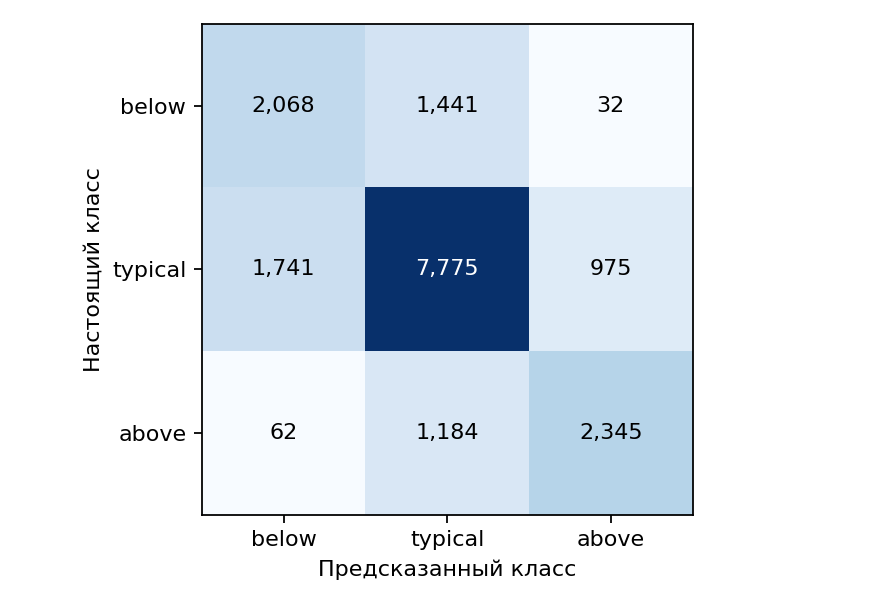

,Unnamed: 0,importance
0,content_type,5.515642
1,is_reshare,4.094356
2,level,3.955961
3,e5_post_pc000,3.671449
4,semantic_soft3_level_delta,3.624998
5,level_to_followers,2.185243
6,n_words_relative20,2.114971
7,n_chars_relative20,1.747262
8,e5_post_pc001,1.460130
9,e5_post_pc005,1.269765


In [4]:
display(pd.DataFrame(metrics["test"]["selected_blend"]["classification_report"]).T)
display(Image(filename=str(RESULTS / "confusion_matrix.png")))
display(pd.read_csv(RESULTS / "feature_importance.csv").head(20))

## Повторный inference и готовый комплект

Штатный evaluator проверяет покрытие всех test-постов. Затем отдельно загружаю сохранённую модель и проверяю, что все предсказания совпадают. PDF и CSV собираются только из измеренных результатов.

In [5]:
run("evaluate.py", "--data", DATA, "--predictions", RESULTS / "selected_blend.csv")
run("predict_lab1_v2.py", "--data", DATA, "--model", RESULTS / "model.joblib", "--output", RESULTS / "reproduced.csv")
original = pd.read_csv(RESULTS / "selected_blend.csv")
repeated = pd.read_csv(RESULTS / "reproduced.csv")
pd.testing.assert_frame_equal(original, repeated)
run("make_report.py", "--results", RESULTS, "--output", OUTPUT / "Lab1_Rostislav_Manzyuk.pdf")
run("tools/prepare_submission.py", "--data", DATA, "--results", RESULTS, "--output", OUTPUT)
print("Все предсказания воспроизвелись. Локальный комплект:")
for path in sorted(OUTPUT.iterdir()):
    print(path.name)

test: 17,623 posts
  macro-F1  0.6593   (primary)
  QWK       0.6018
  accuracy  0.6916
  F1 by class  below 0.5580  typical 0.7443  above 0.6755
  confusion, rows = truth below / typical / above:
      2,068   1,441      32
      1,741   7,775     975
         62   1,184   2,345


results/lab1-v2/reproduced.csv


submission-v2/Lab1_Rostislav_Manzyuk.pdf


Validated submission: {'macro_f1': 0.6593, 'qwk': 0.6018, 'accuracy': 0.6916}
Все предсказания воспроизвелись. Локальный комплект:
Lab1_Rostislav_Manzyuk.pdf
feature_importance.csv
metrics.json
selected_blend.csv
selection.json
validation_experiments.json


## Ограничения

Реакции и профили - снимки на момент сбора. Возраст поста и текущее число подписчиков связаны с процедурой сбора данных. Более ранние реакции test-автора используются в истории так же, как в baseline. Поэтому результат относится к этому офлайн-заданию.

Тексты обрабатываются локально. Сами изображения и видео не используются. Валидационная оценка после подбора параметров может быть оптимистичной; итоговая оценка дана на отдельном официальном test, а доверительный интервал посчитан bootstrap по авторам.

Предыдущая версия уже оценивалась на этом test. В дополнительном раунде он не использовался для выбора кандидатов. Парный bootstrap сравнивает две версии на тех же авторах; это оценка неопределённости разницы, а не доказательство причинного эффекта признаков.